In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs('../figures', exist_ok=True)   # folder where we save our plots

In [3]:
menu_raw = pd.read_excel('DataDictionary.xlsx')
menu_raw.head()

,Restaurant,Restaurant type,Food category,Menu item,Dietary type,Main Ingredient,Calories(Cal),Protein(g),Carbohydrates(g),Fat(g),Sugar(g),Sodium(mg),Serving size(g),Price($)
0,McDonalds,Fast Food,Burger,Big Mac,Non Vegetarian,Beef,580,25.0,45.0,34.0,5.0,1060.0,219,7.79
1,McDonalds,Fast Food,Burger,Quarter Pounder with Cheese,Non Vegetarian,Beef,520,30.0,42.0,26.0,8.0,1140.0,199,7.89
2,McDonalds,Fast Food,Burger,McDouble,Non Vegetarian,Beef,390,22.0,32.0,20.0,6.0,920.0,149,3.29
3,McDonalds,Fast Food,Sandwich,McChicken,Non Vegetarian,Chicken,390,14.0,38.0,21.0,4.0,560.0,170,2.99
4,McDonalds,Fast Food,Sandwich,McCrispy,Non Vegetarian,Chicken,470,26.0,46.0,20.0,9.0,1140.0,200,5.79


**Task 1**

In [4]:
menu_raw.shape


(98, 14)

In [5]:
menu_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98 entries, 0 to 97
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Restaurant        98 non-null     object 
 1   Restaurant type   98 non-null     object 
 2   Food category     98 non-null     object 
 3   Menu item         98 non-null     object 
 4   Dietary type      98 non-null     object 
 5   Main Ingredient   98 non-null     object 
 6   Calories(Cal)     98 non-null     int64  
 7   Protein(g)        98 non-null     float64
 8   Carbohydrates(g)  98 non-null     float64
 9   Fat(g)            98 non-null     float64
 10  Sugar(g)          98 non-null     float64
 11  Sodium(mg)        98 non-null     float64
 12  Serving size(g)   98 non-null     int64  
 13  Price($)          98 non-null     float64
dtypes: float64(6), int64(2), object(6)
memory usage: 10.8+ KB


In [6]:
menu_raw.describe()


,Calories(Cal),Protein(g),Carbohydrates(g),Fat(g),Sugar(g),Sodium(mg),Serving size(g),Price($)
count,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000
mean,697.612245,28.513265,63.054082,36.618367,15.600000,1502.980612,324.551020,10.060306
std,402.008812,20.844845,38.715777,25.317482,19.724311,1162.076589,190.814484,6.743763
min,42.000000,0.000000,1.000000,0.000000,0.000000,0.000000,35.000000,1.790000
25%,401.000000,11.000000,32.250000,18.000000,5.000000,565.000000,170.000000,4.640000
50%,580.000000,24.000000,50.500000,29.000000,8.000000,1240.000000,260.500000,9.190000
75%,1033.750000,45.000000,90.000000,56.000000,19.000000,2172.500000,500.000000,12.835000
max,1930.000000,86.000000,195.000000,115.000000,104.000000,5800.000000,665.000000,29.950000


In [7]:
# 1.1 Missing values
missing = menu_raw.isnull().sum()
print(missing[missing > 0])
print("Total missing values:", menu_raw.isnull().sum().sum())

Series([], dtype: int64)
Total missing values: 0


In [8]:
# 1.2 Extra spaces in text columns
text_cols = ['Restaurant', 'Restaurant type', 'Food category', 'Menu item', 'Dietary type', 'Main Ingredient']

for col in text_cols:
    n = (menu_raw[col] != menu_raw[col].str.strip()).sum()
    print(f"{col}: {n} values with extra spaces")

print()
print("Menu items with trailing spaces:")
print(menu_raw[menu_raw['Menu item'] != menu_raw['Menu item'].str.strip()]['Menu item'].tolist())

Restaurant: 0 values with extra spaces
Restaurant type: 0 values with extra spaces
Food category: 0 values with extra spaces
Menu item: 9 values with extra spaces
Dietary type: 0 values with extra spaces
Main Ingredient: 0 values with extra spaces

Menu items with trailing spaces:
['Sausage, Egg & Cheese Croissant ', 'Beefy 5 Layer Burrito ', 'Jamaican Black Pepper Shrimp ', 'Miso Salmon  ', 'Tossed Green Salad  ', 'Chinese Chicken Salad  ', 'Fresh Strawberry  ', 'Brioche Breakfast Sandwich ', 'Breakfast Potatoes  ']


In [9]:
# 1.3 Labels: are the categories spelled consistently?
for col in ['Restaurant', 'Restaurant type', 'Dietary type']:
    print(menu_raw[col].str.strip().value_counts())
    print()

Restaurant
The Cheesecake Factory    15
Chillis                   15
McDonalds                 14
Taco Bell                 14
Panera                    14
Wendys                    14
Chipotle                  12
Name: count, dtype: int64

Restaurant type
Fast Food        42
Casual Dining    30
Fast Casual      26
Name: count, dtype: int64

Dietary type
Non Vegetarian    61
Vegetarian        37
Name: count, dtype: int64



In [10]:

# 1.4 Duplicates
print("Fully duplicate rows:", menu_raw.duplicated().sum())

# same restaurant + same item name twice (after removing extra spaces)
check = menu_raw.copy()
check['Menu item'] = check['Menu item'].str.strip()
print("Same restaurant and same menu item twice:", check.duplicated(subset=['Restaurant', 'Menu item']).sum())

Fully duplicate rows: 0
Same restaurant and same menu item twice: 0


In [11]:
# 1.5 Zeros and impossible values
num_cols = ['Calories(Cal)', 'Protein(g)', 'Carbohydrates(g)', 'Fat(g)', 'Sugar(g)', 'Sodium(mg)', 'Serving size(g)', 'Price($)']

print("Number of zeros per column:")
print((menu_raw[num_cols] == 0).sum())

print()
print("Sugar greater than carbohydrates (impossible):", (menu_raw['Sugar(g)'] > menu_raw['Carbohydrates(g)']).sum())

# rows with a zero in calories, protein, fat or sodium
menu_raw[(menu_raw[['Calories(Cal)', 'Protein(g)', 'Fat(g)', 'Sodium(mg)']] == 0).any(axis=1)]

Number of zeros per column:
Calories(Cal)       0
Protein(g)          1
Carbohydrates(g)    0
Fat(g)              1
Sugar(g)            7
Sodium(mg)          1
Serving size(g)     0
Price($)            0
dtype: int64

Sugar greater than carbohydrates (impossible): 0


,Restaurant,Restaurant type,Food category,Menu item,Dietary type,Main Ingredient,Calories(Cal),Protein(g),Carbohydrates(g),Fat(g),Sugar(g),Sodium(mg),Serving size(g),Price($)
49,Wendys,Fast Food,Salad,Apple Slices,Vegetarian,Fruit,42,0.0,9.3,0.0,9.3,0.0,35,1.99


In [13]:
# 1.6 Do the calories match the nutrients?
calc_cal = 4 * menu_raw['Protein(g)'] + 4 * menu_raw['Carbohydrates(g)'] + 9 * menu_raw['Fat(g)']
ratio = calc_cal / menu_raw['Calories(Cal)']

print(ratio.describe())
print()
print("Items where calculated and listed calories differ by more than 20%:", ((ratio < 0.8) | (ratio > 1.2)).sum())

count    98.000000
mean      0.998564
std       0.031036
min       0.829412
25%       0.991402
50%       1.000000
75%       1.011857
max       1.085714
dtype: float64

Items where calculated and listed calories differ by more than 20%: 0


In [14]:
# 1.7 Outliers: which values look wrong?
# sodium per calorie by restaurant
sodium_per_cal = menu_raw['Sodium(mg)'] / menu_raw['Calories(Cal)']
print("Median sodium per calorie by restaurant:")
print(sodium_per_cal.groupby(menu_raw['Restaurant']).median().round(2).sort_values())

# all Wendy's items, highest sodium first
menu_raw[menu_raw['Restaurant'] == 'Wendys'][['Menu item', 'Calories(Cal)', 'Sodium(mg)', 'Serving size(g)']].sort_values('Sodium(mg)', ascending=False)

Median sodium per calorie by restaurant:
Restaurant
The Cheesecake Factory    1.67
McDonalds                 1.68
Chipotle                  1.95
Panera                    2.10
Taco Bell                 2.26
Chillis                   2.51
Wendys                    2.62
dtype: float64


,Menu item,Calories(Cal),Sodium(mg),Serving size(g)
42,Baconator,1001,5800.0,300
41,Dave's Double,879,4400.0,300
46,Breakfast Baconator,704,3900.0,230
44,Crispy Chicken Sandwich,404,2500.0,160
43,Spicy Chicken Sandwich,400,2200.0,230
40,Dave's Single,524,2200.0,250
45,Crispy Panko Fish Sandwich,520,1240.0,220
48,"Bacon, Egg & Cheese Biscuit",420,1200.0,150
47,"Sausage, Egg & Cheese Croissant",492,1100.0,170
53,Cinnabon Pull-Apart,550,670.0,180


In [15]:
# 1.8 Other rows that look wrong: very few calories per 100 g for a burrito, burger or sandwich
cal_per_100g = menu_raw['Calories(Cal)'] / menu_raw['Serving size(g)'] * 100
menu_raw[(cal_per_100g < 80) & menu_raw['Food category'].isin(['Burrito', 'Burger', 'Sandwich'])][['Restaurant', 'Menu item', 'Calories(Cal)', 'Serving size(g)']]

,Restaurant,Menu item,Calories(Cal),Serving size(g)
66,Taco Bell,Black Bean Burrito,50,100


**Task 2**

In [18]:
# 2.1 Start from a copy of the original data (the original spreadsheet is never changed)
df = menu_raw.copy()
print("Original shape:", df.shape)

# 2.2 Short column names
df = df.rename(columns={
    'Restaurant': 'restaurant', 'Restaurant type': 'type', 'Food category': 'category',
    'Menu item': 'item', 'Dietary type': 'diet', 'Main Ingredient': 'ingredient',
    'Calories(Cal)': 'calories', 'Protein(g)': 'protein', 'Carbohydrates(g)': 'carbs',
    'Fat(g)': 'fat', 'Sugar(g)': 'sugar', 'Sodium(mg)': 'sodium',
    'Serving size(g)': 'serving_g', 'Price($)': 'price'})

# 2.3 Remove extra spaces from every text column
for col in ['restaurant', 'type', 'category', 'item', 'diet', 'ingredient']:
    df[col] = df[col].str.strip()
print("Menu items with extra spaces left:", (df['item'] != df['item'].str.strip()).sum())

# 2.4 Restaurant names with apostrophes
name_fix = {'McDonalds': "McDonald's", 'Wendys': "Wendy's", 'Chillis': "Chili's", 'The Cheesecake Factory': 'Cheesecake Factory'}
df['restaurant'] = df['restaurant'].replace(name_fix)
print("Restaurants:", sorted(df['restaurant'].unique()))

Original shape: (98, 14)
Menu items with extra spaces left: 0
Restaurants: ['Cheesecake Factory', "Chili's", 'Chipotle', "McDonald's", 'Panera', 'Taco Bell', "Wendy's"]


In [19]:
# 2.5 Fix or flag rows that look wrong
df['data_status'] = 'ok'          # ok / corrected

# Wendy's sodium values were checked against the official Wendy's nutrition information and are correct (just high), so they stay as they are.

# Taco Bell Black Bean Burrito: Taco Bell lists 380 calories (we had 50)
m = (df['restaurant'] == 'Taco Bell') & (df['item'] == 'Black Bean Burrito')
df.loc[m, 'calories'] = 380
df.loc[m, 'data_status'] = 'corrected'

print(df['data_status'].value_counts())

data_status
ok           97
corrected     1
Name: count, dtype: int64


In [20]:
# 2.6 Keep a record of every value we changed (so the changes can be checked)
log = []
for raw_col, new_col in [('Calories(Cal)', 'calories')]:
    changed = menu_raw[raw_col] != df[new_col]
    for i in df.index[changed]:
        log.append({'restaurant': df.loc[i, 'restaurant'], 'item': df.loc[i, 'item'], 'field': new_col,
                    'old_value': menu_raw.loc[i, raw_col], 'new_value': round(df.loc[i, new_col], 1)})
corrections_log = pd.DataFrame(log)
corrections_log['reason'] = 'Taco Bell lists 380 calories'
corrections_log

,restaurant,item,field,old_value,new_value,reason
0,Taco Bell,Black Bean Burrito,calories,50,380,Taco Bell lists 380 calories


In [21]:
# 2.7 New columns so items with different portion sizes can be compared
df['cal_per_100g']       = df['calories'] / df['serving_g'] * 100
df['protein_per_100g']   = df['protein'] / df['serving_g'] * 100
df['sodium_per_100g']    = df['sodium'] / df['serving_g'] * 100
df['sugar_per_100g']     = df['sugar'] / df['serving_g'] * 100
df['price_per_100g']     = df['price'] / df['serving_g'] * 100
df['protein_per_dollar'] = df['protein'] / df['price']
df['sodium_per_cal']     = df['sodium'] / df['calories']

# 2.8 Group the 15 small food categories into 6 bigger groups
group_map = {'Burger': 'Handheld', 'Sandwich': 'Handheld', 'Burrito': 'Handheld', 'Taco': 'Handheld',
             'Quesadilla': 'Handheld', 'Specialty': 'Handheld',
             'Salad': 'Salad/Bowl', 'Bowl': 'Salad/Bowl',
             'Breakfast': 'Breakfast', 'Sweet': 'Sweet',
             'Pasta': 'Entree', 'Seafood': 'Entree', 'Steak': 'Entree', 'Chicken Tenders': 'Entree',
             'Sides': 'Sides'}
df['group'] = df['category'].map(group_map)
print(df['group'].value_counts())

group
Handheld      37
Salad/Bowl    18
Breakfast     15
Sweet         15
Entree        10
Sides          3
Name: count, dtype: int64


In [22]:
# 2.9 Check the result and save the dataset our visualizations will use
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Items with extra spaces:", (df['item'] != df['item'].str.strip()).sum())

print()
print("Median sodium per calorie by restaurant:")
print(df.groupby('restaurant')['sodium_per_cal'].median().round(2).sort_values())

os.makedirs('../data/processed', exist_ok=True)
menu_clean = df.copy()
menu_clean.to_csv('../data/processed/menu_clean.csv', index=False)
corrections_log.to_csv('../data/processed/corrections_log.csv', index=False)
print()
print("Saved ../data/processed/menu_clean.csv and corrections_log.csv")

Shape: (98, 23)
Missing values: 0
Items with extra spaces: 0

Median sodium per calorie by restaurant:
restaurant
Cheesecake Factory    1.67
McDonald's            1.68
Chipotle              1.95
Panera                2.10
Taco Bell             2.24
Chili's               2.51
Wendy's               2.62
Name: sodium_per_cal, dtype: float64

Saved ../data/processed/menu_clean.csv and corrections_log.csv


**Task 3**

In [23]:
# 3.0 Setup
ok = menu_clean.copy()
print("Rows used for exploration:", len(ok))

type_order = ['Fast Food', 'Fast Casual', 'Casual Dining']
rest_order = ["McDonald's", 'Taco Bell', "Wendy's", 'Chipotle', 'Panera', "Chili's", 'Cheesecake Factory']
colors = {'Fast Food': '#d95f02', 'Fast Casual': '#1b9e77', 'Casual Dining': '#7570b3'}

Rows used for exploration: 98


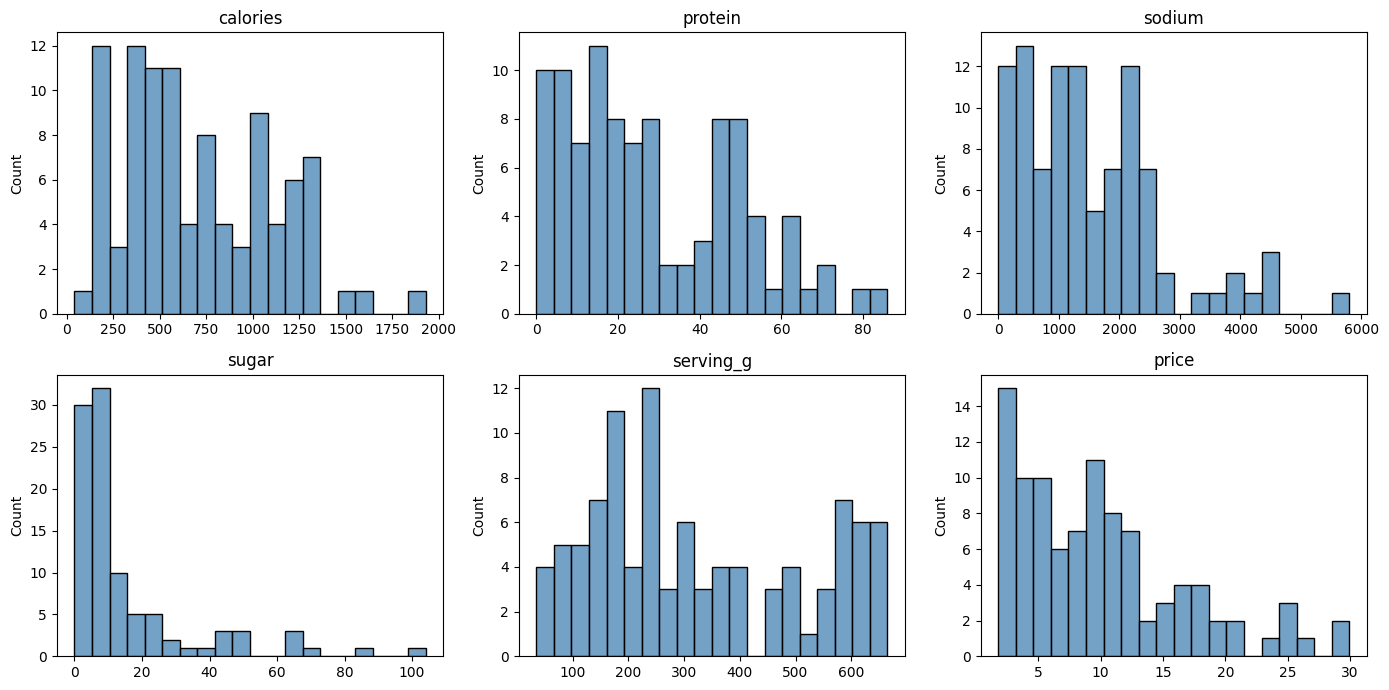

In [24]:
# 3.1 Distributions: what do the numbers look like?
cols = ['calories', 'protein', 'sodium', 'sugar', 'serving_g', 'price']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flatten(), cols):
    sns.histplot(ok[col], bins=20, color='steelblue', ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.savefig('../figures/fig1_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

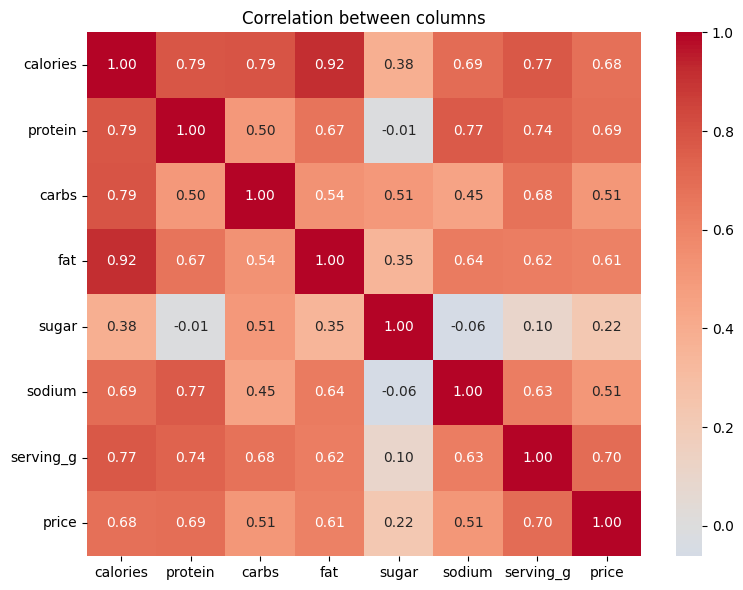

In [25]:
# 3.2 Relationships: which columns move together?
corr_cols = ['calories', 'protein', 'carbs', 'fat', 'sugar', 'sodium', 'serving_g', 'price']
plt.figure(figsize=(8, 6))
sns.heatmap(ok[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation between columns')
plt.tight_layout()
plt.savefig('../figures/fig2_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

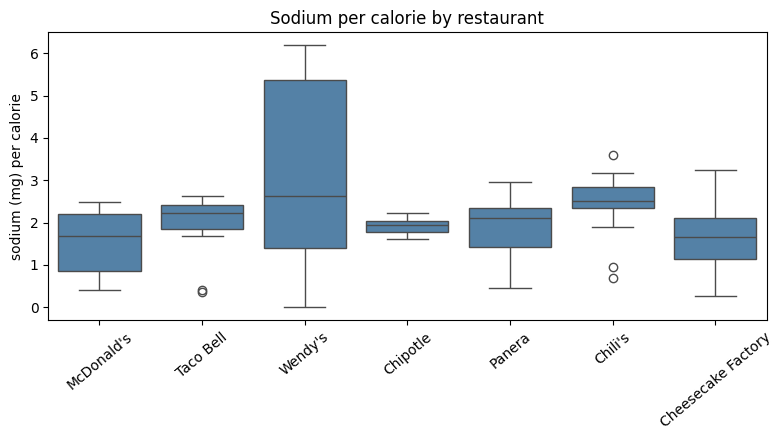

restaurant
Cheesecake Factory    1.67
McDonald's            1.68
Chipotle              1.95
Panera                2.10
Taco Bell             2.24
Chili's               2.51
Wendy's               2.62
Name: sodium_per_cal, dtype: float64


In [26]:
# 3.3 Unusual observations: sodium per calorie by restaurant (Wendy's is high; we checked it and the values are correct)
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=ok, x='restaurant', y='sodium_per_cal', order=rest_order, color='steelblue')
plt.ylabel('sodium (mg) per calorie')
plt.xlabel('')
plt.xticks(rotation=40)
plt.title('Sodium per calorie by restaurant')
plt.tight_layout()
plt.savefig('../figures/fig3_sodium_per_calorie.png', dpi=150, bbox_inches='tight')
plt.show()
print(ok.groupby('restaurant')['sodium_per_cal'].median().round(2).sort_values())

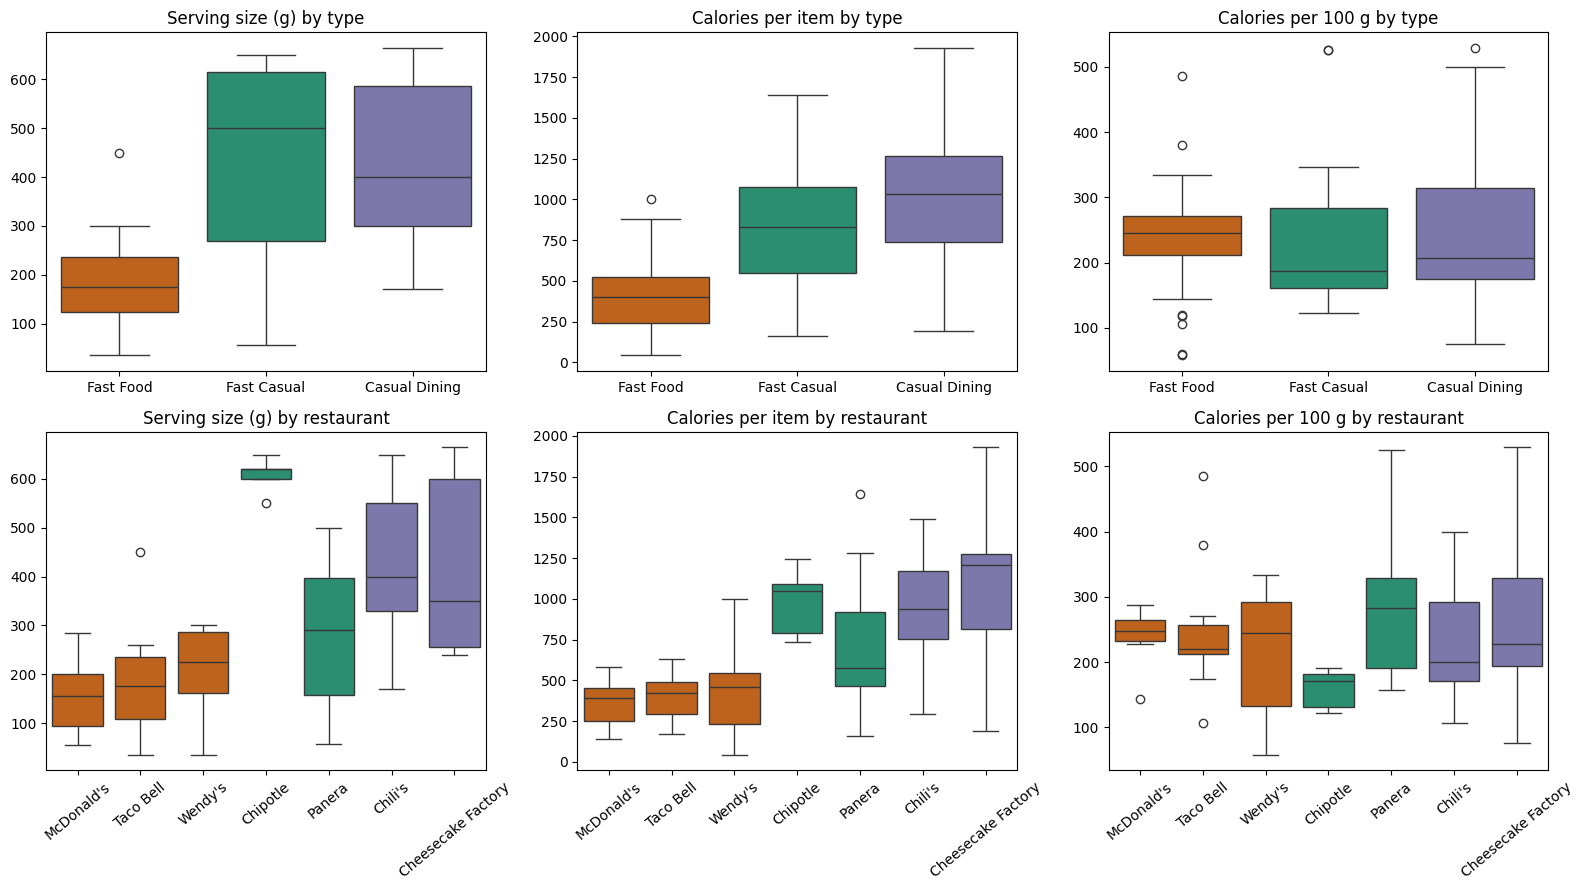

Median per type, total vs per 100 g:
               serving_g  calories  cal_per_100g  protein_per_100g  \
type                                                                 
Fast Food          175.0     402.0         245.0               8.0   
Fast Casual        500.0     828.0         187.0               7.0   
Casual Dining      400.0    1035.0         208.0               9.0   

               sodium_per_100g  
type                            
Fast Food                490.0  
Fast Casual              383.0  
Casual Dining            396.0  


In [27]:
# 3.4 Q1: restaurant types and restaurants. Total size and calories vs calories per 100 g
cols = [('serving_g', 'Serving size (g)'), ('calories', 'Calories per item'), ('cal_per_100g', 'Calories per 100 g')]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (col, title) in zip(axes[0], cols):
    sns.boxplot(data=ok, x='type', y=col, order=type_order, hue='type', palette=colors, legend=False, ax=ax)
    ax.set_title(title + ' by type')
    ax.set_xlabel(''); ax.set_ylabel('')
for ax, (col, title) in zip(axes[1], cols):
    sns.boxplot(data=ok, x='restaurant', y=col, order=rest_order, hue='type', palette=colors, dodge=False, legend=False, ax=ax)
    ax.set_title(title + ' by restaurant')
    ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=40)
plt.tight_layout()
plt.savefig('../figures/fig4_type_vs_restaurant.png', dpi=150, bbox_inches='tight')
plt.show()

print("Median per type, total vs per 100 g:")
print(ok.groupby('type')[['serving_g', 'calories', 'cal_per_100g', 'protein_per_100g', 'sodium_per_100g']].median().loc[type_order].round(0))

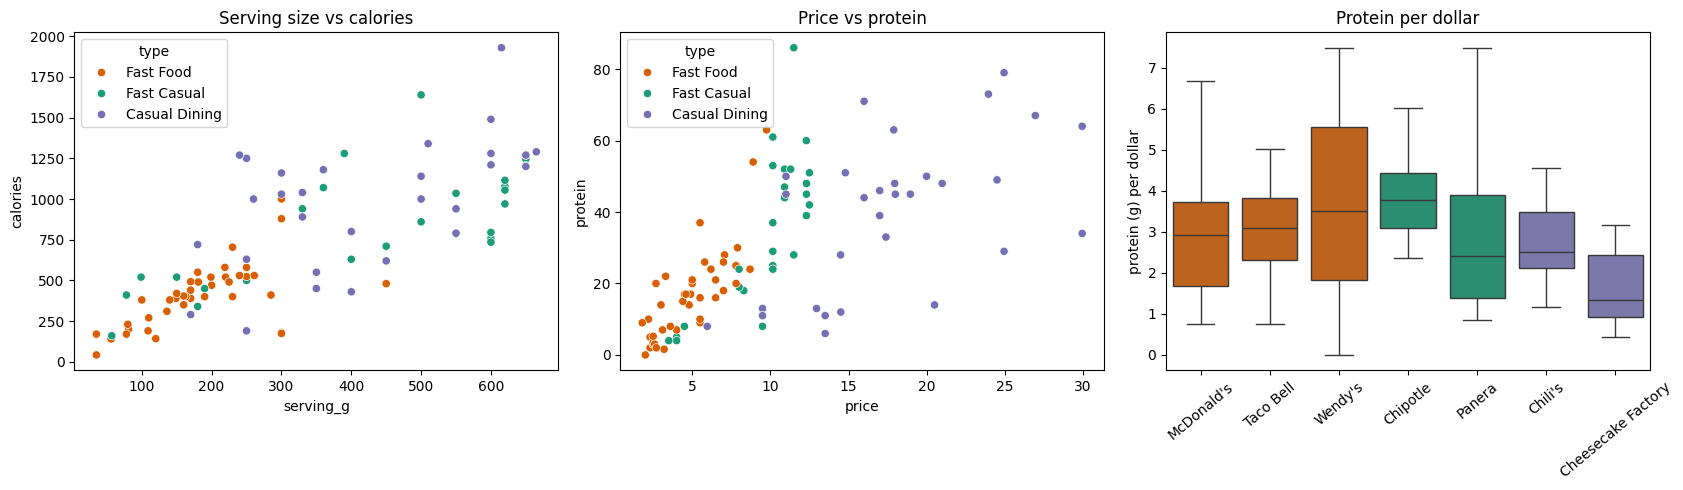

Median calories per 100 g by food group:
group
Salad/Bowl    151.0
Entree        195.0
Sides         200.0
Handheld      235.0
Breakfast     250.0
Sweet         385.0
Name: cal_per_100g, dtype: float64

Salads with more calories than the median burger (580): 9 out of 12

Median protein per dollar by restaurant:
restaurant
Cheesecake Factory    1.34
Panera                2.41
Chili's               2.50
McDonald's            2.92
Taco Bell             3.09
Wendy's               3.51
Chipotle              3.78
Name: protein_per_dollar, dtype: float64


In [28]:
# 3.5 Q2 and Q3: serving size vs calories, price vs protein, and protein per dollar
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.scatterplot(data=ok, x='serving_g', y='calories', hue='type', hue_order=type_order, palette=colors, ax=axes[0])
axes[0].set_title('Serving size vs calories')
sns.scatterplot(data=ok, x='price', y='protein', hue='type', hue_order=type_order, palette=colors, ax=axes[1])
axes[1].set_title('Price vs protein')
sns.boxplot(data=ok, x='restaurant', y='protein_per_dollar', order=rest_order, hue='type', palette=colors, dodge=False, legend=False, ax=axes[2])
axes[2].set_title('Protein per dollar')
axes[2].set_xlabel(''); axes[2].set_ylabel('protein (g) per dollar')
axes[2].tick_params(axis='x', rotation=40)
plt.tight_layout()
plt.savefig('../figures/fig5_relationships.png', dpi=150, bbox_inches='tight')
plt.show()

print("Median calories per 100 g by food group:")
print(ok.groupby('group')['cal_per_100g'].median().round(0).sort_values())
salads = ok[(ok['category'] == 'Salad') & (ok['item'] != 'Apple Slices')]
burger_median = ok[ok['category'] == 'Burger']['calories'].median()
print()
print("Salads with more calories than the median burger (%d):" % burger_median, (salads['calories'] > burger_median).sum(), "out of", len(salads))
print()
print("Median protein per dollar by restaurant:")
print(ok.groupby('restaurant')['protein_per_dollar'].median().round(2).sort_values())

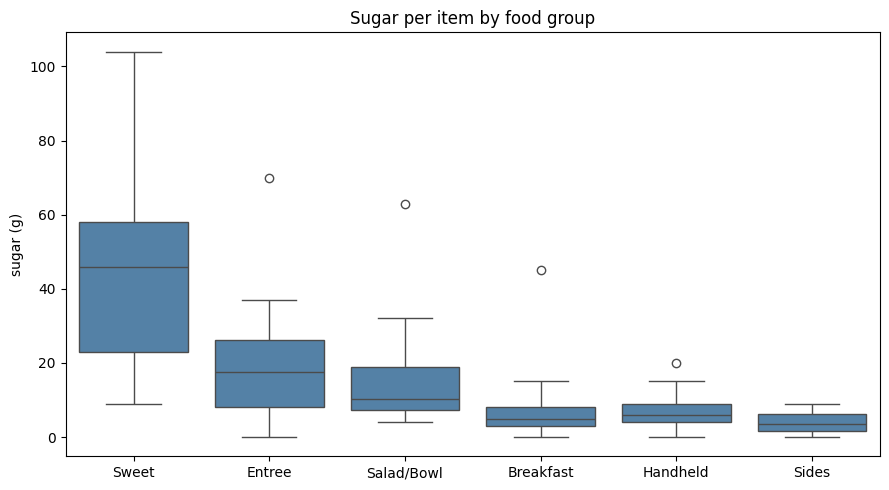

            count  mean  median    max
group                                 
Sweet          15  45.0    46.0  104.0
Entree         10  21.0    18.0   70.0
Salad/Bowl     18  15.0    10.0   63.0
Breakfast      15   8.0     5.0   45.0
Handheld       37   7.0     6.0   20.0
Sides           3   4.0     4.0    9.0

Share of all sugar (g) from non-sweet items: 56%
Outlier limit for non-sweet items: 21.5 g sugar


,restaurant,group,item,sugar
83,Cheesecake Factory,Entree,Jamaican Black Pepper Shrimp,70.0
89,Cheesecake Factory,Salad/Bowl,Chinese Chicken Salad,63.0
8,McDonald's,Breakfast,Hotcakes,45.0
85,Cheesecake Factory,Entree,Fish & Chips,37.0
31,Panera,Salad/Bowl,Fuji Apple Chicken Salad,32.0
84,Cheesecake Factory,Entree,Miso Salmon,27.0
70,Chili's,Entree,Chicken Crispers,24.0
97,Cheesecake Factory,Entree,Four Cheese Pasta,23.0


In [29]:
# 3.6 Q4: sugar by food group
group_order = ['Sweet', 'Entree', 'Salad/Bowl', 'Breakfast', 'Handheld', 'Sides']
plt.figure(figsize=(9, 5))
sns.boxplot(data=ok, x='group', y='sugar', order=group_order, color='steelblue')
plt.xlabel(''); plt.ylabel('sugar (g)')
plt.title('Sugar per item by food group')
plt.tight_layout()
plt.savefig('../figures/fig6_sugar_by_group.png', dpi=150, bbox_inches='tight')
plt.show()

# what an average hides: the biggest single item in each group
print(ok.groupby('group')['sugar'].agg(['count', 'mean', 'median', 'max']).round(0).loc[group_order])

non_sweet = ok[ok['group'] != 'Sweet']
q1 = non_sweet['sugar'].quantile(0.25)
q3 = non_sweet['sugar'].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
print()
print("Share of all sugar (g) from non-sweet items: %.0f%%" % (100 * non_sweet['sugar'].sum() / ok['sugar'].sum()))
print("Outlier limit for non-sweet items: %.1f g sugar" % upper)
non_sweet[non_sweet['sugar'] > upper].sort_values('sugar', ascending=False)[['restaurant', 'group', 'item', 'sugar']]

**Task 4**

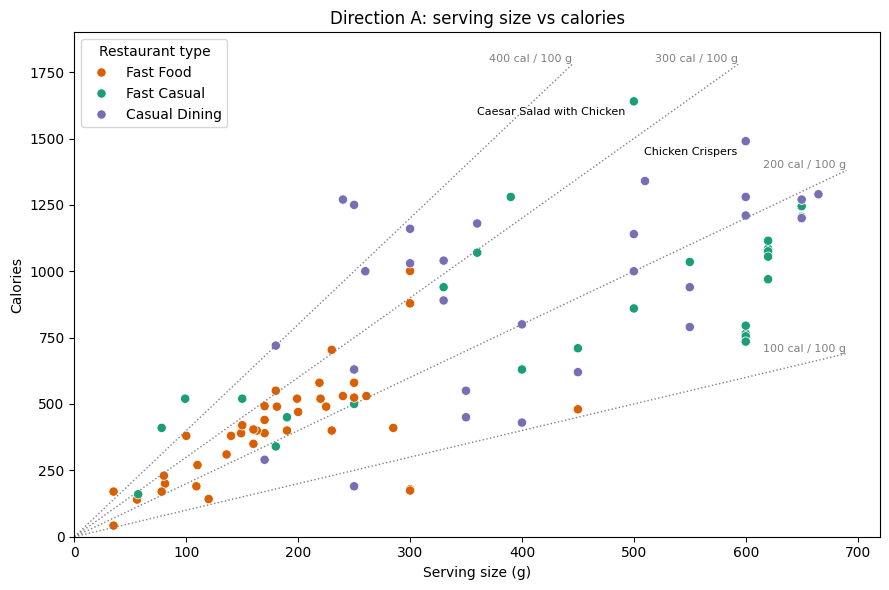

In [30]:
# 4.1 Direction A (Q2, size vs density): serving size vs calories, with lines of equal calories per 100 g
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=ok, x='serving_g', y='calories', hue='type', hue_order=type_order, palette=colors, s=45, ax=ax)
ax.legend(title='Restaurant type', loc='upper left')
for k in [100, 200, 300, 400]:
    x_end = min(690, 1780 * 100 / k)
    ax.plot([0, x_end], [0, x_end * k / 100], ':', color='gray', linewidth=1)
    ax.text(x_end, x_end * k / 100, f'{k} cal / 100 g', fontsize=8, color='gray', ha='right', va='bottom')
ax.set_xlim(0, 720); ax.set_ylim(0, 1900)
top = ok.nlargest(3, 'calories')
for _, r in top.iterrows():
    ax.annotate(r['item'], (r['serving_g'], r['calories']), xytext=(-6, -10), textcoords='offset points', ha='right', fontsize=8)
ax.set_xlabel('Serving size (g)'); ax.set_ylabel('Calories')
ax.set_title('Direction A: serving size vs calories')
plt.tight_layout()
plt.savefig('../figures/fig7_directionA_size_density.png', dpi=150, bbox_inches='tight')
plt.show()

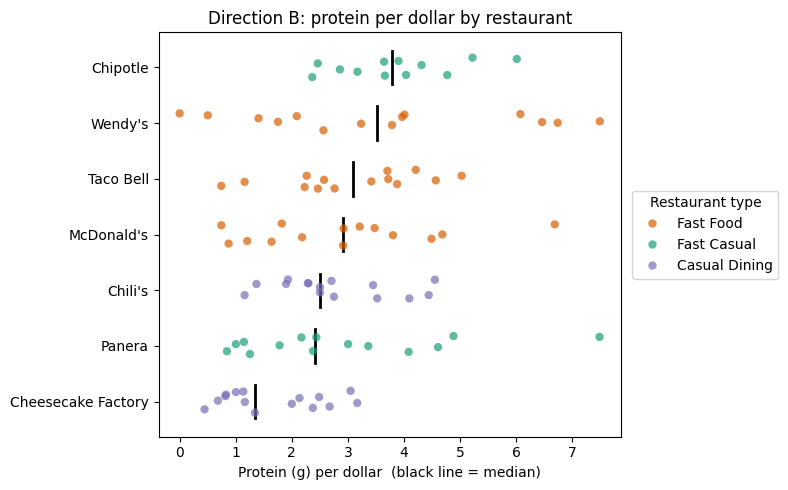

In [31]:
# 4.2 Direction B (Q3, value): protein per dollar, one dot per item, restaurants ranked by median
order = ok.groupby('restaurant')['protein_per_dollar'].median().sort_values(ascending=False).index
rest_type = ok.drop_duplicates('restaurant').set_index('restaurant')['type']
fig, ax = plt.subplots(figsize=(8, 5))
sns.stripplot(data=ok, y='restaurant', x='protein_per_dollar', order=order, hue='type', hue_order=type_order,
              palette=colors, size=6, alpha=0.7, jitter=0.2, ax=ax)
med = ok.groupby('restaurant')['protein_per_dollar'].median()
for i, r in enumerate(order):
    ax.plot([med[r]] * 2, [i - 0.3, i + 0.3], color='black', linewidth=2)
ax.set_xlabel('Protein (g) per dollar  (black line = median)'); ax.set_ylabel('')
ax.legend(title='Restaurant type', loc='center left', bbox_to_anchor=(1.01, 0.5))
ax.set_title('Direction B: protein per dollar by restaurant')
plt.tight_layout()
plt.savefig('../figures/fig8_directionB_protein_per_dollar.png', dpi=150, bbox_inches='tight')
plt.show()

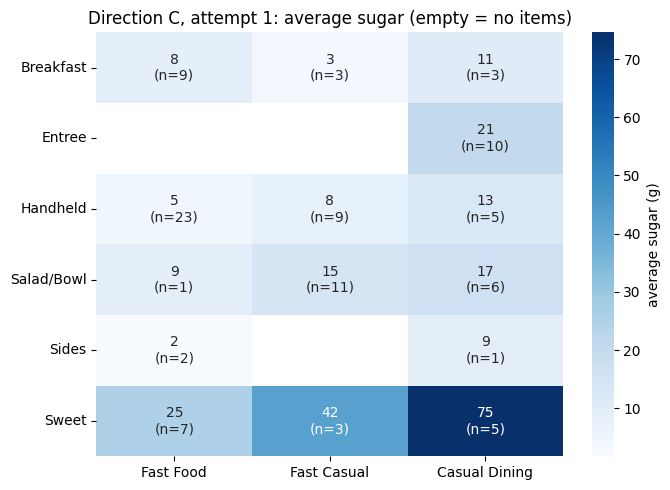

type        Fast Food  Fast Casual  Casual Dining
group                                            
Breakfast           9            3              3
Entree              0            0             10
Handheld           23            9              5
Salad/Bowl          1           11              6
Sides               2            0              1
Sweet               7            3              5


In [32]:
# 4.3 Direction C, attempt 1 (Q4, hidden sugar): our Assignment 1 sketch, a heatmap of average sugar by food group and type
avg = ok.pivot_table(index='group', columns='type', values='sugar', aggfunc='mean')[type_order]
cnt = ok.pivot_table(index='group', columns='type', values='sugar', aggfunc='count')[type_order]
labels = avg.round(0).astype('Int64').astype(str) + '\n(n=' + cnt.fillna(0).astype(int).astype(str) + ')'
plt.figure(figsize=(7, 5))
sns.heatmap(avg, annot=labels, fmt='', cmap='Blues', cbar_kws={'label': 'average sugar (g)'})
plt.xlabel(''); plt.ylabel('')
plt.title('Direction C, attempt 1: average sugar (empty = no items)')
plt.tight_layout()
plt.savefig('../figures/fig9_directionC_heatmap_attempt.png', dpi=150, bbox_inches='tight')
plt.show()
print(cnt.fillna(0).astype(int))

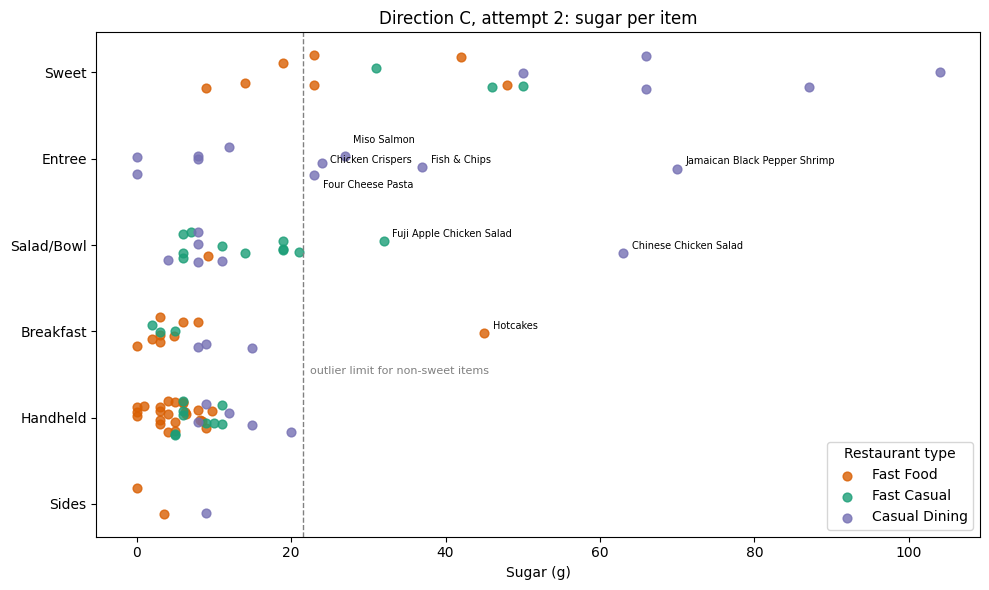

In [33]:
# 4.4 Direction C, attempt 2: every item as a dot, outliers labeled
group_order = ['Sweet', 'Entree', 'Salad/Bowl', 'Breakfast', 'Handheld', 'Sides']
non_sweet = ok[ok['group'] != 'Sweet']
q1, q3 = non_sweet['sugar'].quantile([0.25, 0.75])
limit = q3 + 1.5 * (q3 - q1)

rng = np.random.default_rng(0)
plot_df = ok.copy()
plot_df['y'] = plot_df['group'].map({g: i for i, g in enumerate(group_order)}) + rng.uniform(-0.2, 0.2, len(plot_df))

fig, ax = plt.subplots(figsize=(10, 6))
for t in type_order:
    d = plot_df[plot_df['type'] == t]
    ax.scatter(d['sugar'], d['y'], color=colors[t], s=40, alpha=0.8, label=t)
ax.axvline(limit, color='gray', linestyle='--', linewidth=1)
ax.text(limit + 1, 3.5, 'outlier limit for non-sweet items', fontsize=8, color='gray')
out = plot_df[(plot_df['group'] != 'Sweet') & (plot_df['sugar'] > limit)]
for _, r in out.iterrows():
    dy = {'Miso Salmon': 9, 'Chicken Crispers': 0, 'Four Cheese Pasta': -9}.get(r['item'], 3)
    ax.annotate(r['item'], (r['sugar'], r['y']), xytext=(6, dy), textcoords='offset points', fontsize=7)
ax.set_yticks(range(len(group_order))); ax.set_yticklabels(group_order)
ax.invert_yaxis()
ax.set_xlabel('Sugar (g)')
ax.legend(title='Restaurant type', loc='lower right')
ax.set_title('Direction C, attempt 2: sugar per item')
plt.tight_layout()
plt.savefig('../figures/fig10_directionC_sugar_items.png', dpi=150, bbox_inches='tight')
plt.show()

**Task 5**

In [35]:
# 5.1 Interactive version in Plotly (pip install plotly). Two views side by side:
#     left = size vs calories, right = sugar per item. Hover shows the item; clicking a type in the legend hides it in BOTH views.
import plotly.graph_objects as go
from plotly.subplots import make_subplots

group_order = ['Sweet', 'Entree', 'Salad/Bowl', 'Breakfast', 'Handheld', 'Sides']
rng = np.random.default_rng(0)
pdf = ok.copy()
pdf['y'] = pdf['group'].map({g: i for i, g in enumerate(group_order)}) + rng.uniform(-0.2, 0.2, len(pdf))
pdf['hover'] = ('<b>' + pdf['item'] + '</b><br>' + pdf['restaurant'] + ' (' + pdf['type'] + ')<br>' +
                pdf['serving_g'].astype(int).astype(str) + ' g, ' + pdf['calories'].astype(int).astype(str) + ' cal (' +
                pdf['cal_per_100g'].round(0).astype(int).astype(str) + ' per 100 g)<br>sugar ' +
                pdf['sugar'].astype(int).astype(str) + ' g, $' + pdf['price'].round(2).astype(str))

fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.08,
                    subplot_titles=('Size vs calories', 'Sugar per item'))

# density lines (calories per 100 g) in the left view
for k in [100, 200, 300, 400]:
    x_end = min(690, 1780 * 100 / k)
    fig.add_trace(go.Scatter(x=[0, x_end], y=[0, x_end * k / 100], mode='lines+text', text=['', f'{k} cal/100 g'],
                             textposition='top left', line=dict(color='gray', dash='dot', width=1),
                             hoverinfo='skip', showlegend=False), row=1, col=1)

# one trace per type in each view; the two traces of a type share a legend group
for t in type_order:
    d = pdf[pdf['type'] == t]
    for col, (x, y) in enumerate([('serving_g', 'calories'), ('sugar', 'y')], start=1):
        fig.add_trace(go.Scatter(x=d[x], y=d[y], mode='markers', name=t, legendgroup=t, showlegend=(col == 1),
                                 text=d['hover'], hoverinfo='text', marker=dict(color=colors[t], size=9, opacity=0.85)),
                      row=1, col=col)

# dashed line = outlier limit for non-sweet items (from 3.6)
fig.add_vline(x=upper, line_dash='dash', line_color='gray', row=1, col=2)
fig.update_xaxes(title_text='Serving size (g)', range=[0, 720], row=1, col=1)
fig.update_yaxes(title_text='Calories', range=[0, 1900], row=1, col=1)
fig.update_xaxes(title_text='Sugar (g)', range=[-3, 110], zeroline=False, row=1, col=2)
fig.update_yaxes(tickvals=list(range(6)), ticktext=group_order, range=[5.5, -0.5], zeroline=False, row=1, col=2)
fig.update_layout(template='plotly_white', width=1150, height=520, legend_title_text='Restaurant type (click to hide)', margin=dict(t=50))
fig.show()

In [40]:
# 5.2 Add a restaurant highlight (dropdown at the top left) that fades every other restaurant in both views, then show the figure
data_traces = [i for i, tr in enumerate(fig.data) if tr.mode == 'markers']      # the 6 marker traces
point_rest = [pdf[pdf['type'] == tr.legendgroup]['restaurant'].tolist() for tr in [fig.data[i] for i in data_traces]]

def opacity_for(rest):
    return [[0.85 if (rest is None or r == rest) else 0.12 for r in rests] for rests in point_rest]

buttons = [dict(label='All restaurants', method='restyle', args=[{'marker.opacity': opacity_for(None)}, data_traces])]
for rest in rest_order:
    buttons.append(dict(label=rest, method='restyle', args=[{'marker.opacity': opacity_for(rest)}, data_traces]))

fig.update_layout(updatemenus=[dict(buttons=buttons, direction='down', x=0.0, y=1.18, xanchor='left', showactive=True)])
fig.show()

**Task 6**

In [37]:
# 6.1 Iteration 1: the sugar strip is crowded and does not show the comparison we care about
# (which non-sweet items reach dessert levels?), so replace it with a ranked bar chart of the top non-sweet items.
hand = pdf[pdf['group'] == 'Handheld']
print("Handheld items:", len(hand), "| with 12 g sugar or less:", (hand['sugar'] <= 12).sum())
dessert_median = ok[ok['group'] == 'Sweet']['sugar'].median()
print("Median sugar of desserts: %.0f g" % dessert_median)

top = pdf[pdf['group'] != 'Sweet'].nlargest(15, 'sugar').copy()
top['label'] = np.where(top['item'].duplicated(keep=False), top['item'] + ' (' + top['restaurant'] + ')', top['item'])
print("15th highest non-sweet item: %.0f g" % top['sugar'].min())
high = (pdf['group'] != 'Sweet') & (pdf['sugar'] > upper)      # the outliers from 3.6

def make_fig(ranked, mark_high):
    fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.22, column_widths=[0.45, 0.55],
                        subplot_titles=('Size vs calories', 'Top 15 non-sweet items by sugar' if ranked else 'Sugar per item'))
    for k in [100, 200, 300, 400]:
        x_end = min(690, 1700 * 100 / k)
        fig.add_trace(go.Scatter(x=[0, x_end], y=[0, x_end * k / 100], mode='lines+text', text=['', f'{k} cal/100g'],
                                 textposition='top left', textfont=dict(size=9), line=dict(color='gray', dash='dot', width=1),
                                 hoverinfo='skip', showlegend=False), row=1, col=1)
    for t in type_order:
        d = pdf[pdf['type'] == t]
        h = high[d.index]
        sym = np.where(h & mark_high, 'diamond', 'circle')
        siz = np.where(h & mark_high, 14, 9)
        fig.add_trace(go.Scatter(x=d['serving_g'], y=d['calories'], mode='markers', name=t, legendgroup=t,
                                 text=d['hover'], hoverinfo='text', meta=dict(rest=d['restaurant'].tolist()),
                                 marker=dict(color=colors[t], symbol=sym, size=siz, opacity=0.85,
                                             line=dict(width=np.where(h & mark_high, 1.5, 0), color='black'))), row=1, col=1)
        if ranked:
            r = top[top['type'] == t]
            fig.add_trace(go.Bar(x=r['sugar'], y=r['label'], orientation='h', name=t, legendgroup=t, showlegend=False,
                                 text=r['hover'], hoverinfo='text', textposition='none', meta=dict(rest=r['restaurant'].tolist()),
                                 marker=dict(color=colors[t], opacity=0.85)), row=1, col=2)
        else:
            fig.add_trace(go.Scatter(x=d['sugar'], y=d['y'], mode='markers', name=t, legendgroup=t, showlegend=False,
                                     text=d['hover'], hoverinfo='text', meta=dict(rest=d['restaurant'].tolist()),
                                     marker=dict(color=colors[t], size=9, opacity=0.85)), row=1, col=2)
    fig.add_vline(x=dessert_median if ranked else upper, line_dash='dash', line_color='gray', row=1, col=2)
    fig.update_xaxes(title_text='Serving size (g)', range=[0, 720], row=1, col=1)
    fig.update_yaxes(title_text='Calories', range=[0, 2000], row=1, col=1)
    fig.update_xaxes(title_text='Sugar (g)   (dashed line = ' + ('median dessert, %.0f g)' % dessert_median if ranked else 'outlier limit for non-sweet items)'), range=[0, 110], zeroline=False, row=1, col=2)
    if ranked:
        fig.update_yaxes(categoryorder='array', categoryarray=top['label'].tolist(), autorange='reversed', row=1, col=2)
    else:
        fig.update_yaxes(tickvals=list(range(6)), ticktext=group_order, range=[5.5, -0.5], zeroline=False, row=1, col=2)
    # dropdown: fade every restaurant except the chosen one
    idx = [i for i, tr in enumerate(fig.data) if tr.meta is not None]
    def opac(rest):
        return [[0.85 if (rest is None or r == rest) else 0.12 for r in fig.data[i].meta['rest']] for i in idx]
    buttons = [dict(label='All restaurants', method='restyle', args=[{'marker.opacity': opac(None)}, idx])]
    buttons += [dict(label=r, method='restyle', args=[{'marker.opacity': opac(r)}, idx]) for r in rest_order]
    fig.update_layout(template='plotly_white', width=1150, height=560, margin=dict(t=60, l=60),
                      legend_title_text='Restaurant type (click to hide)',
                      updatemenus=[dict(buttons=buttons, direction='down', x=0.0, y=1.18, xanchor='left')])
    return fig

fig_v2 = make_fig(ranked=True, mark_high=False)
fig_v2.show()

Handheld items: 37 | with 12 g sugar or less: 35
Median sugar of desserts: 46 g
15th highest non-sweet item: 15 g


In [39]:
# 6.2 Iteration 2: the two views were only connected by hovering. Mark the high-sugar items (the diamonds) in the
# size vs calories view too, so you can see whether they are large or dense without hovering.
fig_v3 = make_fig(ranked=True, mark_high=True)
fig_v3.show()

**Task 7**

In [41]:
# 7.1 Current design: ranked sugar view + size vs calories with the high-sugar items marked, plus a note that explains the diamonds
fig_final = make_fig(ranked=True, mark_high=True)
fig_final.add_annotation(xref='paper', yref='paper', x=0.0, y=-0.2, xanchor='left', showarrow=False, font=dict(size=11),
                         text='◆ = non-sweet item with more than %.1f g sugar. Dotted lines = calories per 100 g.' % upper)
fig_final.update_layout(margin=dict(t=60, l=60, b=90))
fig_final.show()